# EcoLink Vision — Model Pipeline Test Notebook

Dry-run and test the **YOLOv8n waste-detection pipeline** (`ml/vision/`) end to end on the
prepared image dataset. Every test block prints its result as **JSON**.

**How to run**
1. Select the kernel from the repo's virtual environment: `Raadhi_Team_OffBeat/.venv` (Python 3.11).
2. *Run All*. Nothing needs editing. Optional knobs are at the top of the cells that use them.

| # | Section | What it tests |
|---|---------|---------------|
| 1 | Setup & config | Environment, class list, thresholds |
| 2 | Load dataset | train / val / test splits with ground-truth boxes |
| 3 | Load model | Fine-tuned weights, class-name contract |
| 4 | **Test 1:** single images | Production `run_inference()` → API JSON per class |
| 5 | **Test 2:** confidence scores | Per-detection confidences, tiers, confirmation flags (JSON) |
| 6 | **Test 3:** class-wise classification | Per-class precision / recall / F1, hazard recall, confusion (JSON) |
| 7 | **Test 4:** detection metrics | Per-class mAP50 / mAP50-95 on the test split (JSON) |
| 8 | **Test 5:** API contract & safety | Assert-style PASS/FAIL checks (JSON) |
| 9 | **Test 6:** latency | CPU inference latency (JSON) |
| 10 | Interactive explorer | Browse any image, tweak the threshold |
| 11 | Your own image | Run the pipeline on any photo |
| 12 | Unit-test suite | Runs the pytest files from inside the notebook |
| 13 | (Optional) retrain | Fine-tune again with `train.py` |
| 14 | Save report | All JSON results → `ml/vision/artifacts/notebook_report.json` |

## 1. Setup & configuration

In [1]:
import os, sys, io, json, time, random, statistics, subprocess
from pathlib import Path
from collections import Counter, defaultdict

# Never let ultralytics pip-install packages on the fly (it can target the wrong Python).
os.environ.setdefault("YOLO_AUTOINSTALL", "false")


def _find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "ml" / "vision" / "config" / "classes.yaml").exists():
            return p
    raise FileNotFoundError("Open this notebook from inside the Raadhi_Team_OffBeat repository.")


REPO_ROOT = _find_repo_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

import numpy as np
import yaml
import torch
import ultralytics
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

from ml.vision.schemas import load_classes_config
from ml.vision.safety import (
    DETECTION_THRESHOLD, HIGH_CONFIDENCE_THRESHOLD, HAZARDOUS_CONFIRMATION_THRESHOLD,
    apply_safety_rules, build_detection,
)
from ml.vision.inference import (
    InferenceError, run_inference, preprocess_image_bytes, _model_names, _label_for_class,
)
from ml.vision.paths import ARTIFACTS_DIR, VISION_DIR, resolve_dataset_yaml
from ml.vision import model_loader


def show_json(obj):
    print(json.dumps(obj, indent=2, default=str))


REPORT = {}  # every section adds its JSON result here; saved in section 14
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

env = {
    "repo_root": str(REPO_ROOT),
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "ultralytics": ultralytics.__version__,
    "device": DEVICE,
}
REPORT["environment"] = env
show_json(env)

{
  "repo_root": "C:\\Users\\XeRush74\\Documents\\Learning & Research Work\\Work\\Hackathons\\Bharat Builds\\Work Repositories\\Echolink-fallback\\Raadhi_Team_OffBeat",
  "python": "3.11.9",
  "torch": "2.5.1+cpu",
  "ultralytics": "8.3.40",
  "device": "cpu"
}


In [2]:
CFG = load_classes_config()
INF_CFG = yaml.safe_load((VISION_DIR / "config" / "inference.yaml").read_text(encoding="utf-8"))
CLASS_NAMES = CFG.class_names
HAZARDOUS = sorted(CFG.hazardous_labels)
IMG_SIZE = INF_CFG["model"]["image_size"]
IOU = INF_CFG["nms"]["iou_threshold"]
MAX_DET = INF_CFG["nms"]["max_detections"]

config_summary = {
    "classes": {i: name for i, name in enumerate(CLASS_NAMES)},
    "hazardous_classes": HAZARDOUS,
    "thresholds": {
        "detection (min confidence returned by the API)": DETECTION_THRESHOLD,
        "high_confidence (HIGH tier)": HIGH_CONFIDENCE_THRESHOLD,
        "hazardous_confirmation (hazardous below this needs user confirmation)": HAZARDOUS_CONFIRMATION_THRESHOLD,
    },
    "inference": {"image_size": IMG_SIZE, "nms_iou": IOU, "max_detections": MAX_DET},
}
REPORT["config"] = config_summary
show_json(config_summary)

{
  "classes": {
    "0": "paper",
    "1": "cardboard",
    "2": "plastic",
    "3": "metal",
    "4": "glass",
    "5": "ewaste",
    "6": "battery"
  },
  "hazardous_classes": [
    "battery",
    "ewaste"
  ],
  "thresholds": {
    "detection (min confidence returned by the API)": 0.5,
    "high_confidence (HIGH tier)": 0.8,
    "hazardous_confirmation (hazardous below this needs user confirmation)": 0.7
  },
  "inference": {
    "image_size": 416,
    "nms_iou": 0.45,
    "max_detections": 50
  }
}


## 2. Load the image dataset

The dataset is already prepared under `ml/vision/data/{train,val,test}` (YOLO format). If the
splits are empty (fresh clone), the next cell rebuilds them from public sources
(about 1 GB download, then auto-labelling and splitting).

| Source | Classes | Notes |
|--------|---------|-------|
| `garbage_*` images: [keremberke/garbage-object-detection](https://huggingface.co/datasets/keremberke/garbage-object-detection) (CC BY 4.0) | paper, cardboard, plastic, metal, glass | Human-annotated boxes |
| `oi_*` images: Open Images V7 val/test | ewaste (phones, laptops, keyboards, TVs …) | Human-annotated boxes |
| `bat_*` images: [khoaliamle/Garbage_Classification_YOLO](https://huggingface.co/datasets/khoaliamle/Garbage_Classification_YOLO) (MIT) | battery | **Auto-labelled** boxes (background subtraction + YOLO-World) |

In [3]:
DATA_DIR = VISION_DIR / "data"
BOOTSTRAP_DATA_IF_MISSING = True   # rebuild the dataset from public sources if the splits are empty
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp"}


def _n_images(split):
    d = DATA_DIR / split / "images"
    return sum(1 for p in d.iterdir() if p.suffix.lower() in IMG_EXTS) if d.exists() else 0


if min(_n_images(s) for s in ("train", "val", "test")) == 0:
    if not BOOTSTRAP_DATA_IF_MISSING:
        raise RuntimeError("Dataset splits are empty. Set BOOTSTRAP_DATA_IF_MISSING = True and re-run.")
    scripts = VISION_DIR / "scripts"
    steps = [
        [str(scripts / "fetch_public_datasets.py"), "--all", "--max-garbage", "3000"],
        [str(scripts / "autolabel_batteries.py"), "--images", str(DATA_DIR / "raw" / "battery_images")],
        [str(scripts / "prepare_dataset.py"), "--source-dir", str(DATA_DIR / "raw" / "garbage_coco"), "--format", "coco"],
        [str(scripts / "prepare_dataset.py"), "--source-dir", str(DATA_DIR / "raw" / "openimages_ewaste"), "--format", "yolo"],
        [str(scripts / "prepare_dataset.py"), "--source-dir", str(DATA_DIR / "raw" / "battery_images"), "--format", "pascal-voc"],
        [str(scripts / "validate_dataset.py"), "--data-dir", str(DATA_DIR)],
    ]
    for step in steps:
        print(">>", Path(step[0]).name, " ".join(step[1:]))
        subprocess.run([sys.executable, *step], cwd=REPO_ROOT, check=True)


def source_of(path: Path) -> str:
    if path.name.startswith("oi_"):
        return "openimages_ewaste"
    if path.name.startswith("bat_"):
        return "battery_autolabelled"
    return "garbage_coco"


def load_split(split):
    records = []
    for img in sorted((DATA_DIR / split / "images").iterdir()):
        if img.suffix.lower() not in IMG_EXTS:
            continue
        boxes = []
        label_file = DATA_DIR / split / "labels" / f"{img.stem}.txt"
        for line in label_file.read_text(encoding="utf-8").splitlines():
            if line.strip():
                c, cx, cy, w, h = line.split()
                boxes.append((int(c), float(cx), float(cy), float(w), float(h)))
        records.append({
            "image": img,
            "boxes": boxes,
            "labels": sorted({CLASS_NAMES[b[0]] for b in boxes}, key=CLASS_NAMES.index),
            "source": source_of(img),
        })
    return records


DATASET = {split: load_split(split) for split in ("train", "val", "test")}

dataset_summary = {}
for split, recs in DATASET.items():
    objs = Counter(CLASS_NAMES[b[0]] for r in recs for b in r["boxes"])
    imgs = Counter(lbl for r in recs for lbl in r["labels"])
    dataset_summary[split] = {
        "images": len(recs),
        "objects": sum(objs.values()),
        "objects_per_class": {c: objs.get(c, 0) for c in CLASS_NAMES},
        "images_per_class": {c: imgs.get(c, 0) for c in CLASS_NAMES},
        "images_per_source": dict(Counter(r["source"] for r in recs)),
    }
REPORT["dataset"] = dataset_summary
show_json(dataset_summary)

{
  "train": {
    "images": 3129,
    "objects": 8442,
    "objects_per_class": {
      "paper": 821,
      "cardboard": 1138,
      "plastic": 1557,
      "metal": 1466,
      "glass": 1993,
      "ewaste": 893,
      "battery": 574
    },
    "images_per_class": {
      "paper": 377,
      "cardboard": 335,
      "plastic": 329,
      "metal": 471,
      "glass": 643,
      "ewaste": 640,
      "battery": 559
    },
    "images_per_source": {
      "battery_autolabelled": 559,
      "garbage_coco": 1930,
      "openimages_ewaste": 640
    }
  },
  "val": {
    "images": 390,
    "objects": 1011,
    "objects_per_class": {
      "paper": 113,
      "cardboard": 101,
      "plastic": 238,
      "metal": 201,
      "glass": 179,
      "ewaste": 106,
      "battery": 73
    },
    "images_per_class": {
      "paper": 59,
      "cardboard": 41,
      "plastic": 35,
      "metal": 59,
      "glass": 66,
      "ewaste": 80,
      "battery": 69
    },
    "images_per_source": {
      "batte

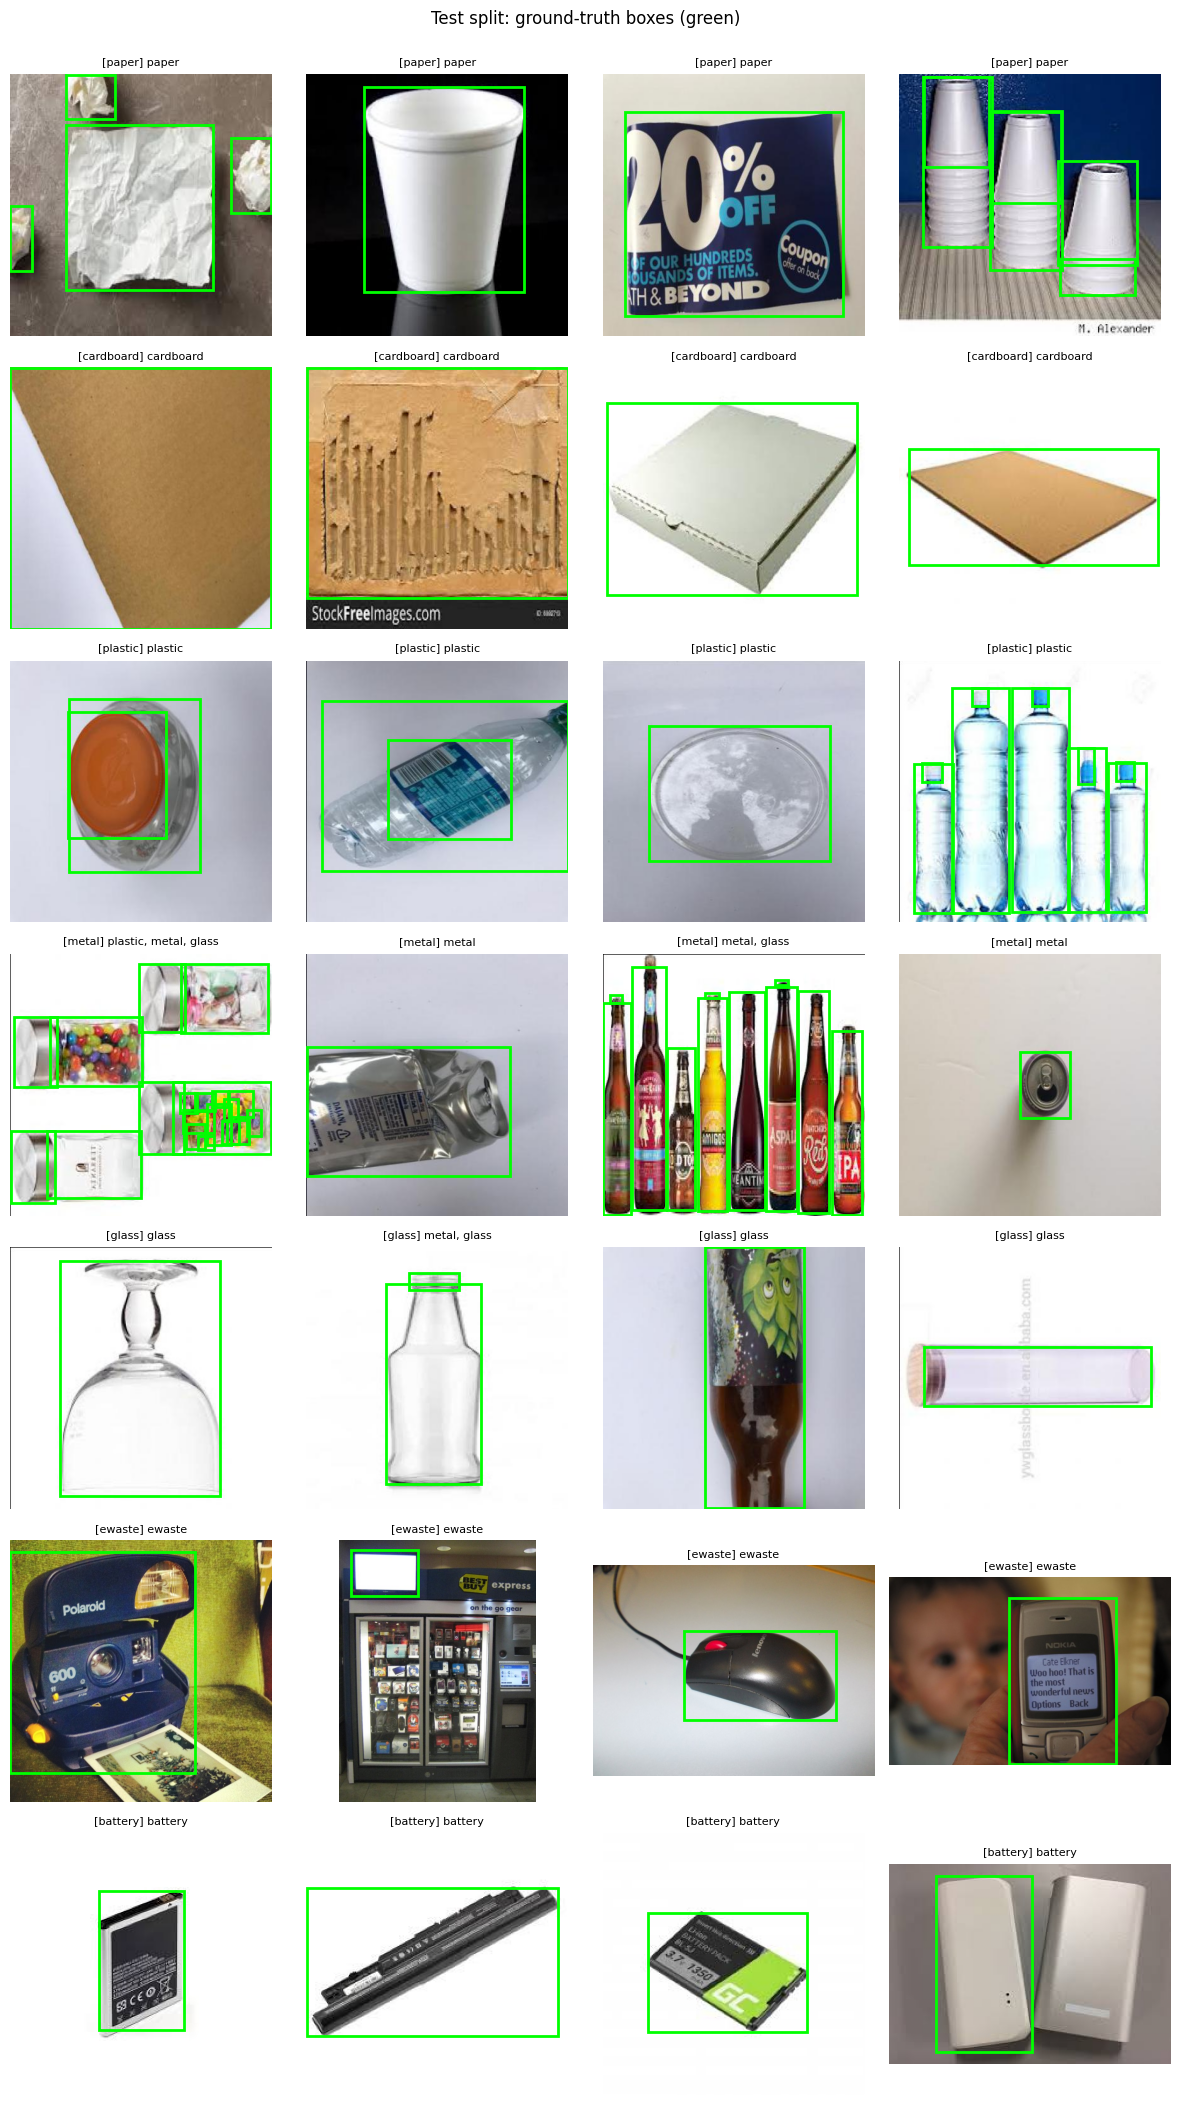

In [4]:
# Ground-truth preview: 4 test images per class
def draw_record(ax, rec, detections=None, title=None):
    img = Image.open(rec["image"]).convert("RGB")
    W, H = img.size
    ax.imshow(img)
    for c, cx, cy, w, h in rec["boxes"]:
        ax.add_patch(patches.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H,
                                       fill=False, edgecolor="lime", linewidth=2))
    for d in detections or []:
        x1, y1, x2, y2 = d["bbox_xyxy"]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=2))
        ax.text(x1, y1, f'{d["label"]} {d["confidence"]:.2f}', color="white", fontsize=7,
                bbox=dict(facecolor="red", alpha=0.7, pad=1, linewidth=0))
    ax.set_title(title or ", ".join(rec["labels"]), fontsize=8)
    ax.axis("off")


rng = random.Random(0)
fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(12, 3 * len(CLASS_NAMES)))
for row, cls in enumerate(CLASS_NAMES):
    pool = [r for r in DATASET["test"] if cls in r["labels"]]
    for col, rec in enumerate(rng.sample(pool, min(4, len(pool)))):
        draw_record(axes[row, col], rec, title=f"[{cls}] {', '.join(rec['labels'])}")
plt.suptitle("Test split: ground-truth boxes (green)", y=1.0)
plt.tight_layout()
plt.show()

## 3. Load the model

Loads the fine-tuned weights from `inference.yaml` (`ml/vision/artifacts/weights/best.pt`) through
the production `model_loader`. The cell also checks the **class-name contract**: the model's
class table must match `classes.yaml` exactly, otherwise IDs would map to the wrong labels.

In [5]:
WEIGHTS = REPO_ROOT / INF_CFG["model"]["weights_path"]
model_loader.reset_model()
if WEIGHTS.exists():
    MODEL = model_loader.load_model(str(WEIGHTS), device=DEVICE)
else:
    print("WARNING: fine-tuned weights not found at", WEIGHTS)
    print("         Falling back to COCO-pretrained yolov8n. Most EcoLink classes cannot be detected.")
    print("         Train first (section 13) for meaningful results.")
    MODEL = model_loader.load_model(device=DEVICE)

MODEL_NAMES = _model_names(MODEL)
TRAINED_IMGSZ = (getattr(MODEL, "ckpt", None) or {}).get("train_args", {}).get("imgsz")
names_in_order = [MODEL_NAMES[i] for i in sorted(MODEL_NAMES)]
FINE_TUNED = names_in_order == CLASS_NAMES

model_info = {
    "weights": str(WEIGHTS) if WEIGHTS.exists() else "yolov8n.pt (COCO fallback)",
    "weights_size_mb": round(WEIGHTS.stat().st_size / 2**20, 2) if WEIGHTS.exists() else None,
    "parameters": sum(p.numel() for p in MODEL.model.parameters()),
    "model_class_names": MODEL_NAMES if FINE_TUNED else f"{len(MODEL_NAMES)} COCO classes",
    "class_contract_matches_classes_yaml": FINE_TUNED,
    "trained_image_size": TRAINED_IMGSZ,
    "inference_image_size": IMG_SIZE,
    "model_class_to_ecolink_label": {
        MODEL_NAMES[i]: _label_for_class(i, MODEL_NAMES, CFG)
        for i in sorted(MODEL_NAMES) if _label_for_class(i, MODEL_NAMES, CFG) is not None
    },
}

# Training summary, if the training run directory is present
results_csv = ARTIFACTS_DIR / "train" / "results.csv"
if results_csv.exists():
    import csv
    rows = list(csv.DictReader(results_csv.open(encoding="utf-8")))
    rows = [{k.strip(): v for k, v in r.items()} for r in rows]
    best = max(rows, key=lambda r: float(r["metrics/mAP50-95(B)"]))
    model_info["training"] = {
        "epochs_run": len(rows),
        "best_epoch": int(float(best["epoch"])),
        "val_mAP50": round(float(best["metrics/mAP50(B)"]), 4),
        "val_mAP50-95": round(float(best["metrics/mAP50-95(B)"]), 4),
        "val_precision": round(float(best["metrics/precision(B)"]), 4),
        "val_recall": round(float(best["metrics/recall(B)"]), 4),
    }
REPORT["model"] = model_info
show_json(model_info)

{
  "weights": "C:\\Users\\XeRush74\\Documents\\Learning & Research Work\\Work\\Hackathons\\Bharat Builds\\Work Repositories\\Echolink-fallback\\Raadhi_Team_OffBeat\\ml\\vision\\artifacts\\weights\\best.pt",
  "weights_size_mb": 5.92,
  "parameters": 3012213,
  "model_class_names": {
    "0": "paper",
    "1": "cardboard",
    "2": "plastic",
    "3": "metal",
    "4": "glass",
    "5": "ewaste",
    "6": "battery"
  },
  "class_contract_matches_classes_yaml": true,
  "trained_image_size": 416,
  "inference_image_size": 416,
  "model_class_to_ecolink_label": {
    "paper": "paper",
    "cardboard": "cardboard",
    "plastic": "plastic",
    "metal": "metal",
    "glass": "glass",
    "ewaste": "ewaste",
    "battery": "battery"
  },
  "training": {
    "epochs_run": 12,
    "best_epoch": 12,
    "val_mAP50": 0.6647,
    "val_mAP50-95": 0.552,
    "val_precision": 0.7874,
    "val_recall": 0.5035
  }
}


## Shared helpers for the tests
`pipeline_json()` is the **production path**: image bytes → `run_inference()` → public API JSON.
`internal_detections()` calls the model with the same NMS settings at a lower confidence (0.25) and
runs the pipeline's own `build_detection()` → `apply_safety_rules()`. That exposes the internal fields
the public API hides: confidence tier, `requires_confirmation`, bounding box, and what the 0.50 cut removes.

In [6]:
LOW_CONF = 0.25  # look below the 0.50 API threshold to see what it filters out


def pipeline_json(image_path: Path) -> dict:
    return run_inference(Path(image_path).read_bytes(), model=MODEL).to_api_dict()


def internal_detections(image_path: Path, conf: float = LOW_CONF):
    image = preprocess_image_bytes(Path(image_path).read_bytes())
    result = MODEL(image, conf=conf, iou=IOU, max_det=MAX_DET, imgsz=IMG_SIZE, verbose=False)[0]
    dets = []
    for cid, score, xyxy in zip(result.boxes.cls.tolist(), result.boxes.conf.tolist(), result.boxes.xyxy.tolist()):
        label = _label_for_class(int(cid), MODEL_NAMES, CFG)
        if label is not None:
            dets.append(build_detection(label, int(cid), float(score), tuple(xyxy)))
    return dets


def det_to_dict(det, gt_labels=None):
    out = {
        "label": det.label,
        "confidence": round(det.confidence, 4),
        "tier": det.confidence_level.value.upper() if det.confidence >= DETECTION_THRESHOLD else "BELOW_THRESHOLD",
        "hazardous": det.hazardous,
        "requires_confirmation": det.requires_confirmation,
        "bbox_xyxy": [round(v, 1) for v in (det.bbox.x1, det.bbox.y1, det.bbox.x2, det.bbox.y2)],
    }
    if gt_labels is not None:
        out["label_in_ground_truth"] = det.label in gt_labels
    return out


def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return round(p, 4), round(r, 4), round(f, 4)


print("helpers ready")

helpers ready


## 4. Test 1: one test image per class through the production pipeline
Prints the exact API response (`{"items": [{"label", "confidence", "hazardous"}]}`) next to the
ground truth. In the figure, green boxes are ground truth and red boxes are detections ≥ 0.50.

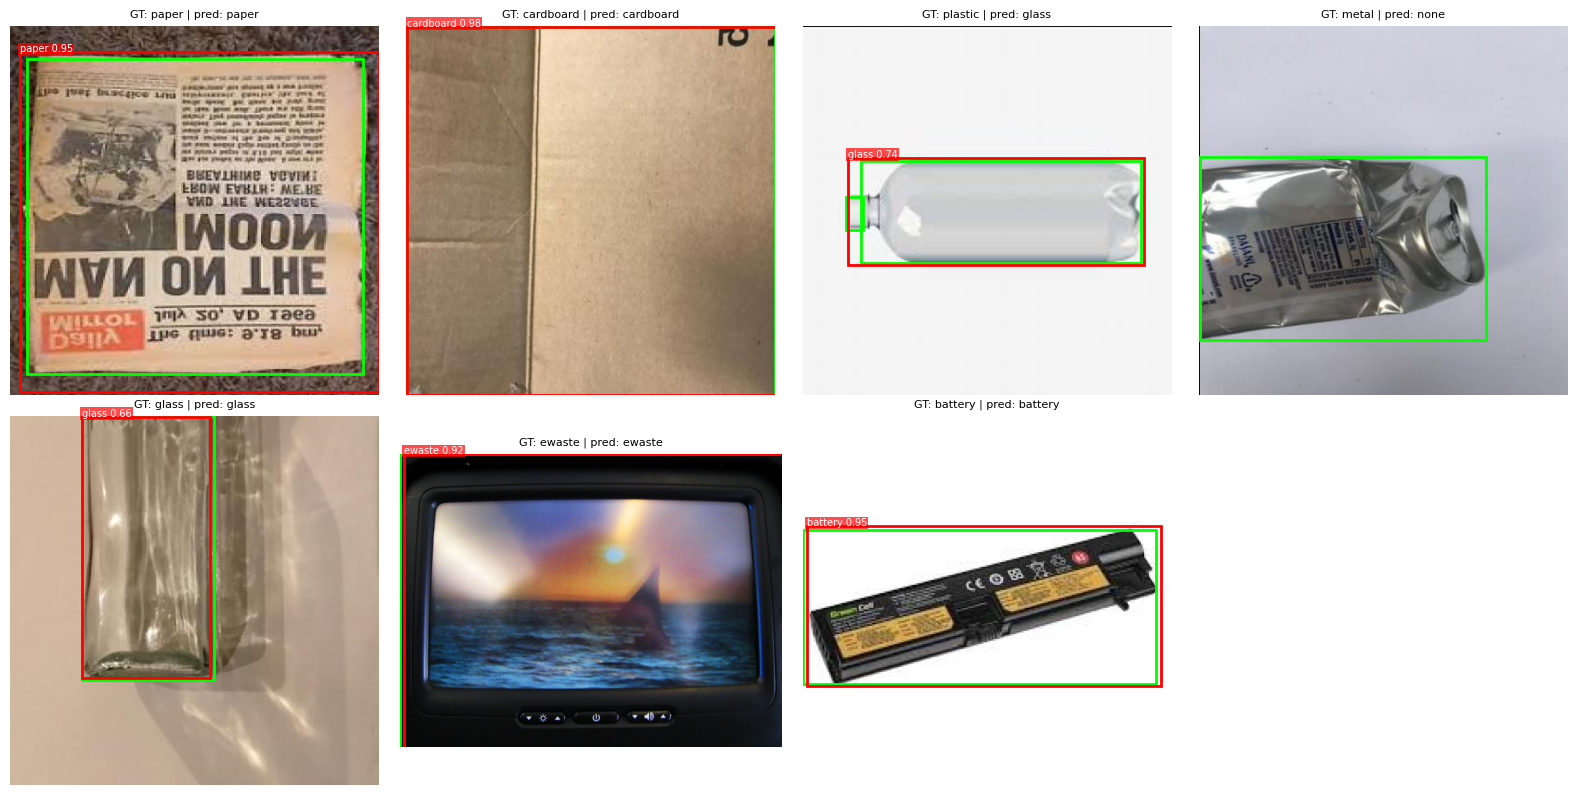

[
  {
    "expected_class": "paper",
    "image": "paper765_jpg.rf.e2ad25410bc684db564ad70b8a8b980f.jpg",
    "ground_truth_labels": [
      "paper"
    ],
    "api_response": {
      "items": [
        {
          "label": "paper",
          "confidence": 0.95,
          "hazardous": false
        }
      ]
    },
    "top_prediction_correct": true
  },
  {
    "expected_class": "cardboard",
    "image": "cardboard1295_jpg.rf.14801051ee679a5fc9473dff0f6c1027.jpg",
    "ground_truth_labels": [
      "cardboard"
    ],
    "api_response": {
      "items": [
        {
          "label": "cardboard",
          "confidence": 0.98,
          "hazardous": false
        }
      ]
    },
    "top_prediction_correct": true
  },
  {
    "expected_class": "plastic",
    "image": "glass1429_jpg.rf.733a1abad7d772631a43b487831be0c5.jpg",
    "ground_truth_labels": [
      "plastic"
    ],
    "api_response": {
      "items": [
        {
          "label": "glass",
          "confidence": 0.74,
     

In [7]:
rng = random.Random(42)
EXAMPLES = {}
for cls in CLASS_NAMES:
    pool = [r for r in DATASET["test"] if r["labels"] == [cls]] or [r for r in DATASET["test"] if cls in r["labels"]]
    EXAMPLES[cls] = rng.choice(pool)

test1 = []
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (cls, rec) in zip(axes.flat, EXAMPLES.items()):
    api = pipeline_json(rec["image"])
    predicted = [i["label"] for i in api["items"]]
    test1.append({
        "expected_class": cls,
        "image": rec["image"].name,
        "ground_truth_labels": rec["labels"],
        "api_response": api,
        "top_prediction_correct": bool(predicted) and predicted[0] in rec["labels"],
    })
    shown = [det_to_dict(d) for d in apply_safety_rules(internal_detections(rec["image"]))]
    draw_record(ax, rec, shown, title=f"GT: {cls} | pred: {predicted[0] if predicted else 'none'}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

REPORT["test1_single_images"] = test1
show_json(test1)

## 5. Test 2: confidence scores (JSON)
Runs **every test image** through the pipeline and records, per image:
* `api_response`: what the public API returns
* `detections`: internal view of each kept detection (confidence, tier, hazardous, `requires_confirmation`, bbox, and whether the label is actually in the image)
* `filtered_below_threshold`: detections between 0.25 and 0.50 that the API drops

It then summarises confidence **per class** and **per tier**. *Tier precision* is the share of
detections whose label really is in that image, which shows whether HIGH-tier detections earn their
"no confirmation needed" status.

In [8]:
MAX_TEST_IMAGES = None   # e.g. 100 for a quicker run; None = whole test split

test_records = DATASET["test"][:MAX_TEST_IMAGES] if MAX_TEST_IMAGES else DATASET["test"]
PER_IMAGE = []
t0 = time.perf_counter()
for rec in test_records:
    gt = set(rec["labels"])
    dets = internal_detections(rec["image"])
    kept = apply_safety_rules(dets)
    PER_IMAGE.append({
        "image": rec["image"].name,
        "source": rec["source"],
        "ground_truth_labels": rec["labels"],
        "api_response": pipeline_json(rec["image"]),
        "detections": [det_to_dict(d, gt) for d in sorted(kept, key=lambda d: -d.confidence)],
        "filtered_below_threshold": [
            {"label": d.label, "confidence": round(d.confidence, 4), "label_in_ground_truth": d.label in gt}
            for d in dets if d.confidence < DETECTION_THRESHOLD
        ],
    })
print(f"{len(PER_IMAGE)} test images processed in {time.perf_counter() - t0:.1f}s\n")
print("First 3 per-image records:")
show_json(PER_IMAGE[:3])

393 test images processed in 107.4s

First 3 per-image records:
[
  {
    "image": "bat_test_battery_164.jpg",
    "source": "battery_autolabelled",
    "ground_truth_labels": [
      "battery"
    ],
    "api_response": {
      "items": [
        {
          "label": "battery",
          "confidence": 0.84,
          "hazardous": true
        }
      ]
    },
    "detections": [
      {
        "label": "battery",
        "confidence": 0.8357,
        "tier": "HIGH",
        "hazardous": true,
        "requires_confirmation": false,
        "bbox_xyxy": [
          63.0,
          67.2,
          182.3,
          212.4
        ],
        "label_in_ground_truth": true
      }
    ],
    "filtered_below_threshold": []
  },
  {
    "image": "bat_test_battery_329.jpg",
    "source": "battery_autolabelled",
    "ground_truth_labels": [
      "battery"
    ],
    "api_response": {
      "items": [
        {
          "label": "battery",
          "confidence": 0.94,
          "hazardous": t

{
  "per_class": {
    "paper": {
      "count": 43,
      "mean": 0.7793,
      "median": 0.8021,
      "min": 0.5172,
      "max": 0.9575,
      "HIGH": 23,
      "MEDIUM": 20,
      "requires_confirmation": 20,
      "precision": 0.7442
    },
    "cardboard": {
      "count": 70,
      "mean": 0.7828,
      "median": 0.7848,
      "min": 0.5092,
      "max": 0.9818,
      "HIGH": 32,
      "MEDIUM": 38,
      "requires_confirmation": 38,
      "precision": 0.9571
    },
    "plastic": {
      "count": 57,
      "mean": 0.7527,
      "median": 0.774,
      "min": 0.5198,
      "max": 0.9831,
      "HIGH": 28,
      "MEDIUM": 29,
      "requires_confirmation": 29,
      "precision": 0.9123
    },
    "metal": {
      "count": 78,
      "mean": 0.734,
      "median": 0.7249,
      "min": 0.5064,
      "max": 0.9504,
      "HIGH": 32,
      "MEDIUM": 46,
      "requires_confirmation": 46,
      "precision": 0.6026
    },
    "glass": {
      "count": 150,
      "mean": 0.8265,
      "m

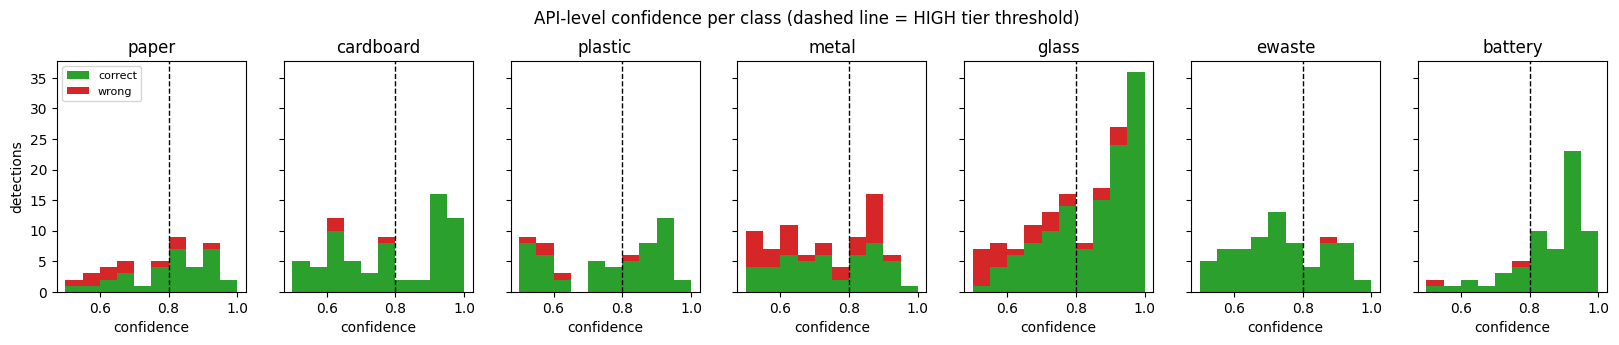

In [9]:
def _stats(values):
    if not values:
        return {"count": 0}
    return {
        "count": len(values),
        "mean": round(statistics.mean(values), 4),
        "median": round(statistics.median(values), 4),
        "min": round(min(values), 4),
        "max": round(max(values), 4),
    }


by_class = defaultdict(list)
tiers = defaultdict(lambda: {"count": 0, "label_in_ground_truth": 0})
confirm = Counter()
for r in PER_IMAGE:
    for d in r["detections"]:
        by_class[d["label"]].append(d)
        tiers[d["tier"]]["count"] += 1
        tiers[d["tier"]]["label_in_ground_truth"] += d["label_in_ground_truth"]
        if d["requires_confirmation"]:
            confirm["hazardous" if d["hazardous"] else "non_hazardous"] += 1
    for d in r["filtered_below_threshold"]:
        tiers["BELOW_THRESHOLD (0.25-0.50, dropped)"]["count"] += 1
        tiers["BELOW_THRESHOLD (0.25-0.50, dropped)"]["label_in_ground_truth"] += d["label_in_ground_truth"]

confidence_report = {
    "per_class": {
        cls: {
            **_stats([d["confidence"] for d in by_class[cls]]),
            "HIGH": sum(d["tier"] == "HIGH" for d in by_class[cls]),
            "MEDIUM": sum(d["tier"] == "MEDIUM" for d in by_class[cls]),
            "requires_confirmation": sum(d["requires_confirmation"] for d in by_class[cls]),
            "precision": round(sum(d["label_in_ground_truth"] for d in by_class[cls]) / len(by_class[cls]), 4) if by_class[cls] else None,
        }
        for cls in CLASS_NAMES
    },
    "per_tier": {
        tier: {**v, "precision": round(v["label_in_ground_truth"] / v["count"], 4) if v["count"] else None}
        for tier, v in tiers.items()
    },
    "requires_confirmation_counts": dict(confirm),
    "api_confidence_overall": _stats([i["confidence"] for r in PER_IMAGE for i in r["api_response"]["items"]]),
}
REPORT["test2_confidence"] = {"summary": confidence_report, "per_image": PER_IMAGE}
show_json(confidence_report)

# Confidence distribution per class: correct vs wrong label
fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(20, 3), sharey=True)
for ax, cls in zip(axes, CLASS_NAMES):
    ok = [d["confidence"] for d in by_class[cls] if d["label_in_ground_truth"]]
    bad = [d["confidence"] for d in by_class[cls] if not d["label_in_ground_truth"]]
    ax.hist([ok, bad], bins=np.linspace(0.5, 1.0, 11), stacked=True, color=["tab:green", "tab:red"], label=["correct", "wrong"])
    ax.axvline(HIGH_CONFIDENCE_THRESHOLD, color="k", ls="--", lw=1)
    ax.set_title(cls)
    ax.set_xlabel("confidence")
axes[0].set_ylabel("detections")
axes[0].legend(fontsize=8)
plt.suptitle("API-level confidence per class (dashed line = HIGH tier threshold)", y=1.05)
plt.show()

## 6. Test 3: class-wise classification (JSON)
Treats each test image as a **multi-label classification** problem. The prediction is the set of
labels in the API response, compared with the set of ground-truth classes in that image.
* per-class precision / recall / F1 / support
* **hazard detection**: an image with e-waste or a battery must come back with at least one `hazardous: true` item. A miss here is the costliest error, because a battery would go to a normal pickup.
* top-1 confusion matrix on single-class images

{
  "images_evaluated": 393,
  "per_class": {
    "paper": {
      "precision": 0.775,
      "recall": 0.62,
      "f1": 0.6889,
      "support_images": 50,
      "predicted_images": 40,
      "tp": 31,
      "fp": 9,
      "fn": 19,
      "tn": 334
    },
    "cardboard": {
      "precision": 0.9286,
      "recall": 0.8125,
      "f1": 0.8667,
      "support_images": 48,
      "predicted_images": 42,
      "tp": 39,
      "fp": 3,
      "fn": 9,
      "tn": 342
    },
    "plastic": {
      "precision": 0.8333,
      "recall": 0.4348,
      "f1": 0.5714,
      "support_images": 46,
      "predicted_images": 24,
      "tp": 20,
      "fp": 4,
      "fn": 26,
      "tn": 343
    },
    "metal": {
      "precision": 0.6038,
      "recall": 0.5818,
      "f1": 0.5926,
      "support_images": 55,
      "predicted_images": 53,
      "tp": 32,
      "fp": 21,
      "fn": 23,
      "tn": 317
    },
    "glass": {
      "precision": 0.7857,
      "recall": 0.9296,
      "f1": 0.8516,
      "su

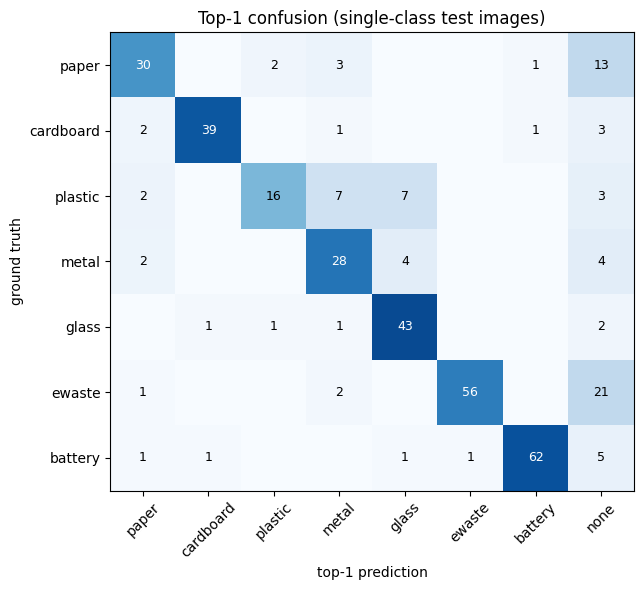

In [10]:
counts = {c: {"tp": 0, "fp": 0, "fn": 0, "tn": 0} for c in CLASS_NAMES}
exact, no_pred = 0, 0
hz = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}
missed_hazard_images = []
confusion = {c: Counter() for c in CLASS_NAMES}

for r in PER_IMAGE:
    gt = set(r["ground_truth_labels"])
    items = r["api_response"]["items"]
    pred = {i["label"] for i in items}
    exact += pred == gt
    no_pred += not items
    for c in CLASS_NAMES:
        key = ("tp" if c in pred else "fn") if c in gt else ("fp" if c in pred else "tn")
        counts[c][key] += 1
    gt_h = bool(gt & set(HAZARDOUS))
    pred_h = any(i["hazardous"] for i in items)
    hz[("tp" if pred_h else "fn") if gt_h else ("fp" if pred_h else "tn")] += 1
    if gt_h and not pred_h:
        missed_hazard_images.append(r["image"])
    if len(gt) == 1:
        confusion[next(iter(gt))][items[0]["label"] if items else "none"] += 1

per_class = {}
for c in CLASS_NAMES:
    p, rcl, f1 = prf(counts[c]["tp"], counts[c]["fp"], counts[c]["fn"])
    per_class[c] = {
        "precision": p, "recall": rcl, "f1": f1,
        "support_images": counts[c]["tp"] + counts[c]["fn"],
        "predicted_images": counts[c]["tp"] + counts[c]["fp"],
        **counts[c],
    }
micro = prf(sum(v["tp"] for v in counts.values()), sum(v["fp"] for v in counts.values()), sum(v["fn"] for v in counts.values()))
hp, hr, hf = prf(hz["tp"], hz["fp"], hz["fn"])

classification_report = {
    "images_evaluated": len(PER_IMAGE),
    "per_class": per_class,
    "macro_avg": {k: round(statistics.mean(per_class[c][k] for c in CLASS_NAMES), 4) for k in ("precision", "recall", "f1")},
    "micro_avg": dict(zip(("precision", "recall", "f1"), micro)),
    "exact_match_ratio": round(exact / len(PER_IMAGE), 4),
    "images_with_no_prediction": no_pred,
    "hazard_detection": {
        "precision": hp, "recall": hr, "f1": hf, **hz,
        "missed_hazardous_images": missed_hazard_images,
    },
    "top1_confusion_single_class_images": {c: dict(confusion[c]) for c in CLASS_NAMES},
}
REPORT["test3_classification"] = classification_report
show_json(classification_report)

cols = CLASS_NAMES + ["none"]
mat = np.array([[confusion[g].get(p, 0) for p in cols] for g in CLASS_NAMES])
norm = mat / np.maximum(mat.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45)
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
for i in range(len(CLASS_NAMES)):
    for j in range(len(cols)):
        if mat[i, j]:
            ax.text(j, i, mat[i, j], ha="center", va="center", color="white" if norm[i, j] > 0.5 else "black", fontsize=9)
ax.set_xlabel("top-1 prediction")
ax.set_ylabel("ground truth")
ax.set_title("Top-1 confusion (single-class test images)")
plt.tight_layout()
plt.show()

## 7. Test 4: detection metrics per class (mAP, JSON)
Standard object-detection evaluation on the test split with ultralytics' validator:
box-level precision, recall, mAP@0.5 and mAP@0.5:0.95. It uses `conf=0.001`, the standard
setting for mAP; the 0.50 operating point is already covered by Tests 2–3.

In [11]:
if not FINE_TUNED:
    detection_report = {"skipped": "model classes do not match classes.yaml (no fine-tuned weights)"}
else:
    val = MODEL.val(
        data=str(resolve_dataset_yaml("ml/vision/config/dataset.yaml")),
        split="test", imgsz=IMG_SIZE, conf=0.001, device=DEVICE, batch=8,
        plots=False, verbose=False, project=str(ARTIFACTS_DIR / "notebook_runs"), name="val", exist_ok=True,
    )
    box = val.box
    detection_report = {
        "overall": {
            "precision": round(float(box.mp), 4),
            "recall": round(float(box.mr), 4),
            "mAP50": round(float(box.map50), 4),
            "mAP50-95": round(float(box.map), 4),
        },
        "per_class": {
            CLASS_NAMES[int(c)]: {
                "precision": round(float(box.p[i]), 4),
                "recall": round(float(box.r[i]), 4),
                "mAP50": round(float(box.ap50[i]), 4),
                "mAP50-95": round(float(box.ap[i]), 4),
            }
            for i, c in enumerate(box.ap_class_index)
        },
        "image_size": IMG_SIZE,
    }
REPORT["test4_detection_metrics"] = detection_report
show_json(detection_report)

Ultralytics 8.3.40  Python-3.11.9 torch-2.5.1+cpu CPU (11th Gen Intel Core(TM) i5-1135G7 2.40GHz)


val: Scanning C:\Users\XeRush74\Documents\Learning & Research Work\Work\Hackathons\Bharat Builds\Work Repositories\Echolink-fallback\Raadhi_Team_OffBeat\ml\vision\data\test\labels.cache... 393 images, 0 backgrounds, 0 corrupt: 100%|██████████| 393/393 [00:00<?, ?it/s]

val: Scanning C:\Users\XeRush74\Documents\Learning & Research Work\Work\Hackathons\Bharat Builds\Work Repositories\Echolink-fallback\Raadhi_Team_OffBeat\ml\vision\data\test\labels.cache... 393 images, 0 backgrounds, 0 corrupt: 100%|██████████| 393/393 [00:00<?, ?it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):   0%|          | 0/50 [00:00<?, ?it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):   2%|▏         | 1/50 [00:00<00:29,  1.65it/s]

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 50/50 [00:42<00:00,  1.27it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 50/50 [00:42<00:00,  1.18it/s]

                   all        393        909      0.622      0.535      0.574      0.429


Speed: 1.2ms preprocess, 87.2ms inference, 0.0ms loss, 7.8ms postprocess per image


{
  "overall": {
    "precision": 0.6222,
    "recall": 0.5352,
    "mAP50": 0.5744,
    "mAP50-95": 0.4286
  },
  "per_class": {
    "paper": {
      "precision": 0.4994,
      "recall": 0.381,
      "mAP50": 0.4093,
      "mAP50-95": 0.3121
    },
    "cardboard": {
      "precision": 0.559,
      "recall": 0.625,
      "mAP50": 0.6421,
      "mAP50-95": 0.4979
    },
    "plastic": {
      "precision": 0.6175,
      "recall": 0.2732,
      "mAP50": 0.3849,
      "mAP50-95": 0.2191
    },
    "metal": {
      "precision": 0.3982,
      "recall": 0.3835,
      "mAP50": 0.3235,
      "mAP50-95": 0.2188
    },
    "glass": {
      "precision": 0.662,
      "recall": 0.6598,
      "mAP50": 0.6682,
      "mAP50-95": 0.4714
    },
    "ewaste": {
      "precision": 0.6956,
      "recall": 0.5741,
      "mAP50": 0.6381,
      "mAP50-95": 0.4804
    },
    "battery": {
      "precision": 0.9235,
      "recall": 0.8501,
      "mAP50": 0.955,
      "mAP50-95": 0.8001
    }
  },
  "image_size":

## 8. Test 5: API contract & safety checks (PASS/FAIL, JSON)
Assertions on the outputs collected in Test 2, plus direct probes of the input-validation and
safety rules.

In [12]:
import io as _io

CHECKS = {}


def check(name, fn):
    try:
        result = fn()
        CHECKS[name] = "SKIP: " + result if isinstance(result, str) else "PASS"
    except AssertionError as e:
        CHECKS[name] = f"FAIL: {e}"
    except Exception as e:  # noqa: BLE001
        CHECKS[name] = f"ERROR: {type(e).__name__}: {e}"


ALL_ITEMS = [i for r in PER_IMAGE for i in r["api_response"]["items"]]
ALL_RESPONSES = [r["api_response"] for r in PER_IMAGE]


def _items_keys():
    assert all(set(r) == {"items"} for r in ALL_RESPONSES), "top-level keys must be exactly {'items'}"
    bad = [i for i in ALL_ITEMS if set(i) != {"label", "confidence", "hazardous"}]
    assert not bad, f"unexpected item keys: {bad[:3]}"


def _labels_canonical():
    bad = {i["label"] for i in ALL_ITEMS} - set(CLASS_NAMES)
    assert not bad, f"non-canonical labels: {bad}"


def _confidence_range_and_rounding():
    bad = [i for i in ALL_ITEMS if not (DETECTION_THRESHOLD <= i["confidence"] <= 1.0) or round(i["confidence"], 2) != i["confidence"]]
    assert not bad, f"bad confidences: {bad[:3]}"


def _sorted_desc():
    bad = [r for r in ALL_RESPONSES if [i["confidence"] for i in r["items"]] != sorted((i["confidence"] for i in r["items"]), reverse=True)]
    assert not bad, f"{len(bad)} responses not sorted"


def _one_item_per_label():
    bad = [r for r in ALL_RESPONSES if len({i['label'] for i in r['items']}) != len(r["items"])]
    assert not bad, f"{len(bad)} responses with duplicate labels"


def _hazard_flag_deterministic():
    bad = [i for i in ALL_ITEMS if i["hazardous"] != (i["label"] in HAZARDOUS)]
    assert not bad, f"wrong hazardous flags: {bad[:3]}"


def _expect_inference_error(payload, status=400):
    try:
        run_inference(payload, model=MODEL)
    except InferenceError as e:
        assert e.status_code == status, f"status {e.status_code} != {status}"
        return
    raise AssertionError("no InferenceError raised")


def _encode(img, fmt):
    buf = _io.BytesIO()
    img.save(buf, format=fmt)
    return buf.getvalue()


def _truncated():
    data = _encode(Image.effect_noise((256, 256), 64).convert("RGB"), "JPEG")
    _expect_inference_error(data[: len(data) // 3])


def _odd_colour_modes():
    for mode, fmt in (("RGBA", "PNG"), ("L", "PNG"), ("RGB", "WEBP")):
        out = run_inference(_encode(Image.new(mode, (320, 240)), fmt), model=MODEL).to_api_dict()
        assert "items" in out


def _deterministic():
    img = DATASET["test"][0]["image"]
    assert pipeline_json(img) == pipeline_json(img), "same image gave different responses"


def _confirmation_rules():
    assert build_detection("battery", 6, 0.62, (0, 0, 1, 1)).requires_confirmation is True
    assert build_detection("battery", 6, 0.97, (0, 0, 1, 1)).requires_confirmation is False
    assert build_detection("plastic", 2, 0.75, (0, 0, 1, 1)).requires_confirmation is True
    assert build_detection("plastic", 2, 0.95, (0, 0, 1, 1)).requires_confirmation is False


def _image_size_matches_training():
    if TRAINED_IMGSZ is None:
        return "checkpoint does not record its training image size"
    assert IMG_SIZE == TRAINED_IMGSZ, f"inference.yaml image_size={IMG_SIZE} but weights were trained at {TRAINED_IMGSZ}"


def _coco_fallback_guard():
    coco_weights = VISION_DIR / "artifacts" / "weights" / "yolov8n.pt"
    if not coco_weights.exists():
        return "COCO yolov8n.pt not cached locally"
    from ultralytics import YOLO
    from ultralytics.utils import ASSETS
    coco = YOLO(str(coco_weights))
    labels = [i["label"] for i in run_inference((ASSETS / "bus.jpg").read_bytes(), model=coco).items]
    assert "ewaste" not in labels and "paper" not in labels, f"bus/person mislabelled as {labels}"


check("response_has_only_items_key_and_item_fields", _items_keys)
check("labels_are_canonical", _labels_canonical)
check("confidence_between_0.50_and_1_and_rounded_2dp", _confidence_range_and_rounding)
check("items_sorted_by_confidence_desc", _sorted_desc)
check("one_item_per_label", _one_item_per_label)
check("hazardous_flag_matches_hazard_list", _hazard_flag_deterministic)
check("corrupt_jpeg_rejected_400", lambda: _expect_inference_error(b"\xff\xd8\xff" + b"garbage" * 20))
check("truncated_jpeg_rejected_400", _truncated)
check("gif_rejected_400", lambda: _expect_inference_error(_encode(Image.new("RGB", (8, 8)), "GIF")))
check("oversized_image_rejected_400", lambda: _expect_inference_error(b"\xff\xd8\xff" + b"\x00" * (5 * 2**20)))
check("http_url_rejected_400", lambda: _expect_inference_error("http://bucket.s3.amazonaws.com/x.jpg"))
check("non_aws_host_rejected_400", lambda: _expect_inference_error("https://evil.example.com/x.jpg"))
check("metadata_ip_rejected_400", lambda: _expect_inference_error("https://169.254.169.254/latest/meta-data"))
check("rgba_grayscale_webp_inputs_accepted", _odd_colour_modes)
check("deterministic_output", _deterministic)
check("requires_confirmation_rules", _confirmation_rules)
check("inference_image_size_matches_training", _image_size_matches_training)
check("coco_fallback_never_mislabels_bus_or_person", _coco_fallback_guard)

contract_report = {
    "passed": sum(v == "PASS" for v in CHECKS.values()),
    "failed": sum(v.startswith(("FAIL", "ERROR")) for v in CHECKS.values()),
    "skipped": sum(v.startswith("SKIP") for v in CHECKS.values()),
    "checks": CHECKS,
}
REPORT["test5_contract"] = contract_report
show_json(contract_report)

{
  "passed": 18,
  "failed": 0,
  "skipped": 0,
  "checks": {
    "response_has_only_items_key_and_item_fields": "PASS",
    "labels_are_canonical": "PASS",
    "confidence_between_0.50_and_1_and_rounded_2dp": "PASS",
    "items_sorted_by_confidence_desc": "PASS",
    "one_item_per_label": "PASS",
    "hazardous_flag_matches_hazard_list": "PASS",
    "corrupt_jpeg_rejected_400": "PASS",
    "truncated_jpeg_rejected_400": "PASS",
    "gif_rejected_400": "PASS",
    "oversized_image_rejected_400": "PASS",
    "http_url_rejected_400": "PASS",
    "non_aws_host_rejected_400": "PASS",
    "metadata_ip_rejected_400": "PASS",
    "rgba_grayscale_webp_inputs_accepted": "PASS",
    "deterministic_output": "PASS",
    "requires_confirmation_rules": "PASS",
    "inference_image_size_matches_training": "PASS",
    "coco_fallback_never_mislabels_bus_or_person": "PASS"
  }
}


## 9. Test 6: inference latency (JSON)

In [13]:
N_LATENCY = 30
sample = [r["image"].read_bytes() for r in DATASET["test"][:N_LATENCY]]
run_inference(sample[0], model=MODEL)  # warm-up
lat = []
for data in sample:
    t = time.perf_counter()
    run_inference(data, model=MODEL)
    lat.append((time.perf_counter() - t) * 1000)
lat.sort()
latency_report = {
    "device": DEVICE,
    "images": len(lat),
    "image_size": IMG_SIZE,
    "mean_ms": round(statistics.mean(lat), 1),
    "p50_ms": round(statistics.median(lat), 1),
    "p95_ms": round(lat[int(0.95 * (len(lat) - 1))], 1),
    "max_ms": round(lat[-1], 1),
    "throughput_img_per_s": round(1000 / statistics.mean(lat), 2),
}
REPORT["test6_latency"] = latency_report
show_json(latency_report)

{
  "device": "cpu",
  "images": 30,
  "image_size": 416,
  "mean_ms": 145.2,
  "p50_ms": 141.6,
  "p95_ms": 196.4,
  "max_ms": 221.2,
  "throughput_img_per_s": 6.89
}


## 10. Interactive explorer
Pick a split, a class and an image index. Green boxes are ground truth and red boxes are detections at or above the threshold
slider. The JSON shows the production API response and the internal detection details.

In [14]:
try:
    import ipywidgets as W
    from IPython.display import display, clear_output

    split_w = W.Dropdown(options=["test", "val", "train"], value="test", description="split")
    class_w = W.Dropdown(options=["(any)"] + CLASS_NAMES, value="(any)", description="class")
    index_w = W.IntSlider(min=0, max=0, value=0, description="index", continuous_update=False)
    thresh_w = W.FloatSlider(min=0.25, max=0.95, step=0.05, value=DETECTION_THRESHOLD, description="threshold", continuous_update=False)
    out = W.Output()

    def _pool():
        recs = DATASET[split_w.value]
        return recs if class_w.value == "(any)" else [r for r in recs if class_w.value in r["labels"]]

    def _refresh_index(*_):
        index_w.max = max(len(_pool()) - 1, 0)
        index_w.value = 0
        _render()

    def _render(*_):
        pool = _pool()
        with out:
            clear_output(wait=True)
            if not pool:
                print("no images")
                return
            rec = pool[index_w.value]
            gt = set(rec["labels"])
            dets = [det_to_dict(d, gt) for d in internal_detections(rec["image"]) if d.confidence >= thresh_w.value]
            fig, ax = plt.subplots(figsize=(7, 7))
            draw_record(ax, rec, dets, title=f"{rec['image'].name} | GT: {', '.join(rec['labels'])}")
            plt.show()
            show_json({"api_response": pipeline_json(rec["image"]), "detections_at_threshold": dets})

    split_w.observe(_refresh_index, "value")
    class_w.observe(_refresh_index, "value")
    index_w.observe(_render, "value")
    thresh_w.observe(_render, "value")
    display(W.HBox([split_w, class_w]), W.HBox([index_w, thresh_w]), out)
    _refresh_index()
except ImportError:
    print("ipywidgets not installed: `pip install ipywidgets` to enable the explorer")

Output()

## 11. Test your own image
Set `MY_IMAGE` to any JPEG/PNG/WebP on disk. If it's left as `None`, a random test image is used.

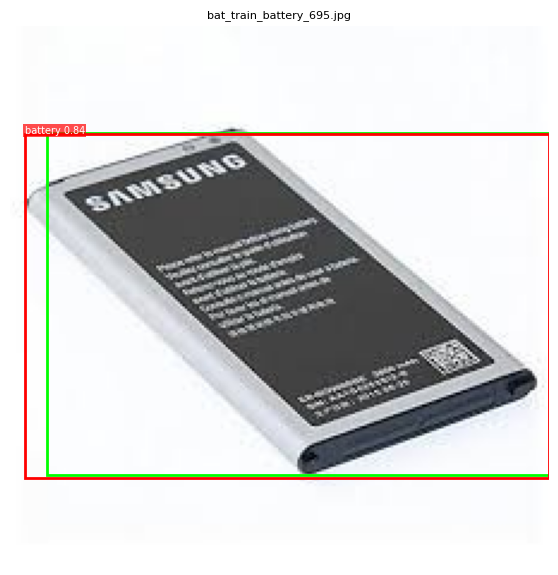

{
  "image": "C:\\Users\\XeRush74\\Documents\\Learning & Research Work\\Work\\Hackathons\\Bharat Builds\\Work Repositories\\Echolink-fallback\\Raadhi_Team_OffBeat\\ml\\vision\\data\\test\\images\\bat_train_battery_695.jpg",
  "ground_truth_labels": [
    "battery"
  ],
  "api_response": {
    "items": [
      {
        "label": "battery",
        "confidence": 0.84,
        "hazardous": true
      }
    ]
  },
  "detections": [
    {
      "label": "battery",
      "confidence": 0.8381,
      "tier": "HIGH",
      "hazardous": true,
      "requires_confirmation": false,
      "bbox_xyxy": [
        5.6,
        44.5,
        224.3,
        188.3
      ]
    }
  ]
}


In [15]:
MY_IMAGE = None   # e.g. r"C:\Users\me\Pictures\waste.jpg"

path = Path(MY_IMAGE) if MY_IMAGE else random.choice(DATASET["test"])["image"]
try:
    api = pipeline_json(path)
    dets = [det_to_dict(d) for d in apply_safety_rules(internal_detections(path))]
    rec = {"image": path, "boxes": [], "labels": []}
    for r in DATASET["test"]:
        if r["image"] == path:
            rec = r
    fig, ax = plt.subplots(figsize=(7, 7))
    draw_record(ax, rec, dets, title=path.name)
    plt.show()
    show_json({"image": str(path), "ground_truth_labels": rec["labels"] or "unknown", "api_response": api, "detections": dets})
except InferenceError as e:
    show_json({"image": str(path), "error": str(e), "status_code": e.status_code})

## 12. Run the unit-test suite
Runs the original five ML test files plus the added ones (handler, model loader, robustness,
dataset scripts) with pytest, in a subprocess.

In [16]:
TEST_FILES = [
    "tests/test_class_mapping.py", "tests/test_confidence.py", "tests/test_vision_inference.py",
    "tests/test_vision_safety.py", "tests/test_vision_schema.py",
    "tests/test_vision_handler.py", "tests/test_vision_model_loader.py",
    "tests/test_vision_robustness.py", "tests/test_dataset_scripts.py", "tests/test_vision_model_integration.py",
]
proc = subprocess.run(
    [sys.executable, "-m", "pytest", *[f for f in TEST_FILES if (REPO_ROOT / f).exists()], "-q", "-p", "no:cacheprovider", "-rfEx", "--color=no"],
    cwd=REPO_ROOT, capture_output=True, text=True,
)
tail = proc.stdout.strip().splitlines()[-12:]
import re
summary_line = next((l for l in reversed(tail) if re.search(r"\d+ (passed|failed)", l)), "")
pytest_report = {
    "exit_code": proc.returncode,
    "summary": summary_line.strip("= "),
    "counts": {k: int(v) for v, k in re.findall(r"(\d+) (passed|failed|xfailed|xpassed|skipped|errors?)", summary_line)},
    "output_tail": tail,
}
REPORT["unit_tests"] = pytest_report
show_json(pytest_report)

{
  "exit_code": 0,
  "summary": "235 passed, 1 xfailed in 78.01s (0:01:18)",
  "counts": {
    "passed": 235,
    "xfailed": 1
  },
  "output_tail": [
    "........................................................................ [ 30%]",
    "........................................................................ [ 61%]",
    "......................................................x................. [ 91%]",
    "....................                                                     [100%]",
    "=========================== short test summary info ===========================",
    "XFAIL tests/test_vision_robustness.py::test_redirect_to_metadata_endpoint_is_not_followed - Known gap: fetch_image_bytes uses urllib's default opener, which follows 3xx redirects without re-validating the target, so an allowed *.amazonaws.com host can redirect the fetch to 169.254.169.254 (SSRF). Fix: open via a HTTPRedirectHandler subclass whose redirect_request() calls validate_image_url().",
    "235 p

## 13. (Optional) retrain the model
Off by default. Set `RUN_TRAINING = True` to fine-tune again with the repo's `train.py`.
Expect roughly 50 min/epoch on a laptop CPU, or about 12 min/epoch on a small CUDA GPU. The best weights are
copied to `ml/vision/artifacts/weights/best.pt`; re-run the notebook from section 3 afterwards.

In [17]:
RUN_TRAINING = False
TRAIN_ARGS = ["--epochs", "12", "--batch-size", "16", "--imgsz", "416", "--workers", "2", "--patience", "5"]

cmd = [sys.executable, str(VISION_DIR / "train.py"), *TRAIN_ARGS]
if RUN_TRAINING:
    subprocess.run(cmd, cwd=REPO_ROOT, check=True)
else:
    print("Training skipped. Command that would run:\n ", " ".join(cmd))

Training skipped. Command that would run:
  C:\Users\XeRush74\Documents\Learning & Research Work\Work\Hackathons\Bharat Builds\Work Repositories\Echolink-fallback\Raadhi_Team_OffBeat\.venv\Scripts\python.exe C:\Users\XeRush74\Documents\Learning & Research Work\Work\Hackathons\Bharat Builds\Work Repositories\Echolink-fallback\Raadhi_Team_OffBeat\ml\vision\train.py --epochs 12 --batch-size 16 --imgsz 416 --workers 2 --patience 5


## 14. Save the full JSON report

In [18]:
out_path = ARTIFACTS_DIR / "notebook_report.json"
out_path.write_text(json.dumps(REPORT, indent=2, default=str), encoding="utf-8")
headline = {
    "report_file": str(out_path),
    "model": REPORT["model"]["weights"],
    "test_images": len(PER_IMAGE),
    "classification_macro_f1": REPORT["test3_classification"]["macro_avg"]["f1"],
    "hazard_recall": REPORT["test3_classification"]["hazard_detection"]["recall"],
    "detection_mAP50": REPORT["test4_detection_metrics"].get("overall", {}).get("mAP50"),
    "contract_checks": f'{REPORT["test5_contract"]["passed"]} passed, {REPORT["test5_contract"]["failed"]} failed',
    "latency_p50_ms": REPORT["test6_latency"]["p50_ms"],
    "unit_tests": REPORT["unit_tests"]["summary"],
}
show_json(headline)

{
  "report_file": "C:\\Users\\XeRush74\\Documents\\Learning & Research Work\\Work\\Hackathons\\Bharat Builds\\Work Repositories\\Echolink-fallback\\Raadhi_Team_OffBeat\\ml\\vision\\artifacts\\notebook_report.json",
  "model": "C:\\Users\\XeRush74\\Documents\\Learning & Research Work\\Work\\Hackathons\\Bharat Builds\\Work Repositories\\Echolink-fallback\\Raadhi_Team_OffBeat\\ml\\vision\\artifacts\\weights\\best.pt",
  "test_images": 393,
  "classification_macro_f1": 0.7582,
  "hazard_recall": 0.7881,
  "detection_mAP50": 0.5744,
  "contract_checks": "18 passed, 0 failed",
  "latency_p50_ms": 141.6,
  "unit_tests": "235 passed, 1 xfailed in 78.01s (0:01:18)"
}
